# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

**Домбровський Богдан Володимирович**

1. Один рядок змінює межі документів та збільшує пікову пам’ять; передача самого рядка як ітератора подає символи замість документів.
2. Нормалізація, попереднє розбиття, модель підслів, постобробка (спецтокени), декодування.
3. `<unk>` — невідомий токен, `<eos>` — кінець документа.
4. Менший BPE словник дає менше злиттів; за повного байтового алфавіту невідомі токени не потрібні. Експеримент нижче.
5. EOS відокремлює документи, інакше модель вчиться штучним переходам між ними.
6. Одновимірні цілочисельні тензори ID токенів.
7. `assert torch.equal(x[:,1:], y[:,:-1])` перевіряє зсув.
8. Нижній трикутник дозволяє бачити минуле і поточну позицію; без маски модель підглядає майбутні токени.
9. Найкращий і останній збігаються, якщо остання оцінка мінімальна; фактичний результат нижче.
10. Частіша оцінка дає більше точок, але не гарантує гладкості; час вимірюється нижче.
11. softmax(z/T): велике T вирівнює ймовірності, мале концентрує їх.
12. top_p залишає найменшу множину токенів із сумарною ймовірністю не меншою p.
13. Thinking додає режим міркування в шаблоні Qwen; фактичні приклади в демо, якість не гарантована.

In [1]:
%pip install -q "transformers>=4.51,<5" datasets tokenizers sentencepiece tensorboard evaluate gradio accelerate scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, time, gc, random, math, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from torch import nn
from torch.nn import functional as F
from torch.utils.tensorboard import SummaryWriter
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from transformers import AutoTokenizer, pipeline
from IPython.display import display
root=Path('/content/lab3' if Path('/content').exists() else 'lab3'); root.mkdir(exist_ok=True)
for sub in ['models','runs','tokenizers']: (root/sub).mkdir(exist_ok=True)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(42); torch.manual_seed(42)
rows=[]
def bpe(texts,size):
    tok=Tokenizer(models.BPE(unk_token='<unk>')); tok.pre_tokenizer=pre_tokenizers.ByteLevel(add_prefix_space=False); tok.decoder=decoders.ByteLevel()
    tok.train_from_iterator(texts,trainers.BpeTrainer(vocab_size=size,special_tokens=['<unk>','<eos>'],initial_alphabet=pre_tokenizers.ByteLevel.alphabet()))
    return tok
poems=load_dataset('RudyiVT/ukrainian-poems',split='train[:3000]')['context_poem']; poems=[x for x in poems if x]
for size in [16000,5000]:
    tok=bpe(poems,size); enc=tok.encode_batch(poems); ids=[i for e in enc for i in e.ids]; print(size, 'actual',tok.get_vocab_size(),'mean',len(ids)/len(enc),'unk',np.mean(np.array(ids)==tok.token_to_id('<unk>')))
del poems,enc,ids,tok


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…):   0%|          | 0.00/58.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

16000 actual 16000 mean 1111.4556666666667 unk 0.0
5000 actual 5000 mean 1314.8666666666666 unk 0.0


---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [3]:
# Українські новини: незалежний від поезії корпус
stream=load_dataset('cc_news', 'uk', split='train', streaming=True) if False else load_dataset('wikimedia/wikipedia','20231101.uk',split='train',streaming=True)
texts=[r['text'][:5000] for r in stream.take(1800) if len(r['text'])>200]
assert len(texts)>100
cut=int(len(texts)*.9); train_texts=texts[:cut]; val_texts=texts[cut:]; corpus_text='\n\n'.join(texts)
print(len(texts),len(corpus_text),texts[0][:300])

README.md: 0.00B [00:00, ?B/s]

1768 6316849 Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки м


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [4]:
base=AutoTokenizer.from_pretrained('Qwen/Qwen2.5-0.5B-Instruct'); warm=base.train_new_from_iterator(train_texts,500); print('warmup',len(warm)); del base,warm
bt=bpe(train_texts,500)
wp=Tokenizer(models.WordPiece(unk_token='<unk>')); wp.pre_tokenizer=pre_tokenizers.Whitespace(); wp.train_from_iterator(train_texts,trainers.WordPieceTrainer(vocab_size=500,special_tokens=['<unk>','<eos>']))
ug=Tokenizer(models.Unigram()); ug.pre_tokenizer=pre_tokenizers.Metaspace(); ug.train_from_iterator(train_texts,trainers.UnigramTrainer(vocab_size=500,unk_token='<unk>',special_tokens=['<unk>','<eos>']))
comparison=[]
for name,tok in [('BPE',bt),('WordPiece',wp),('Unigram',ug)]:
    tok.save(str(root/'tokenizers'/f'{name}.json')); enc=tok.encode_batch(val_texts[:20]); comparison.append(dict(algorithm=name,vocab=tok.get_vocab_size(),tokens=sum(len(e.ids) for e in enc),common=len(tok.encode('Україна').ids),rare=len(tok.encode('електроенцефалографія').ids),unknown=sum(e.ids.count(tok.token_to_id('<unk>')) for e in enc)))
comp=pd.DataFrame(comparison); display(comp); print('Найкоротші послідовності:',comp.loc[comp.tokens.idxmin(),'algorithm'],'; BPE зливає часті пари, WordPiece оцінює зв’язок частин, Unigram оптимізує ймовірність сегментації. Невідомі токени можуть штучно скорочувати результат.')

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

warmup 500


,algorithm,vocab,tokens,common,rare,unknown
0,BPE,500,24445,4,13,0
1,WordPiece,762,34105,7,21,0
2,Unigram,500,32011,6,17,0


Найкоротші послідовності: BPE ; BPE зливає часті пари, WordPiece оцінює зв’язок частин, Unigram оптимізує ймовірність сегментації. Невідомі токени можуть штучно скорочувати результат.


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [5]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


In [6]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


In [7]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)




class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


In [8]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


torch.Size([2298778]) torch.Size([158882])
minigpt_v1 Україна — цео а в у, що (до 17ово.
Події




�Народилисьмсан Вов вСен — — уос — (.
 best 500 last 500
minigpt_v2 Україна — цера, ват, що і, якаово.
Події Ву зи, американський с, уенноовосолрон та в Індіїу, український, що.
 best 500 last 500
minigpt_v3 Україна — цео а в у, що (до 17ово.
Події




�Народилисьмсан Вов вСен — — уос — (.
 best 500 last 500


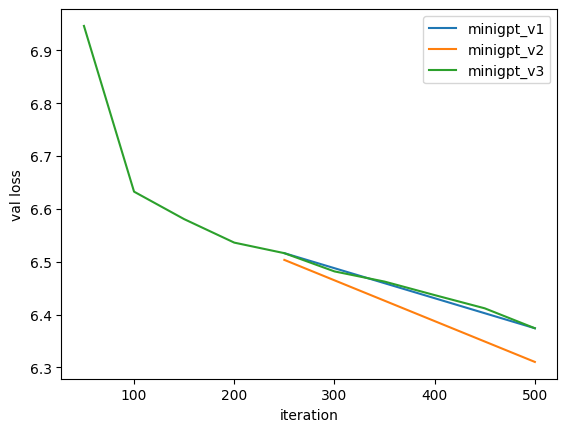

,model,val_loss,seconds,layers,interval,best_step,parameters
0,minigpt_v1,6.374028,54.28293,2,250,500,615440
1,minigpt_v2,6.310268,70.25350,3,250,500,726992
2,minigpt_v3,6.374028,58.75143,2,50,500,615440


Переможець: minigpt_v2 ; додатковий час частішої оцінки: 4.468500691999907
Глибина порівнюється v1/v2, частота оцінки v1/v3; якість генерації оцінюємо за надрукованими текстами.


In [9]:
tok=bpe(train_texts,2000); tok.save(str(root/'tokenizers'/'minigpt.json'))
def encode_docs(docs):
    chunks=[]
    for i in range(0,len(docs),64):
        chunks.extend(np.array(e.ids+[tok.token_to_id('<eos>')],dtype=np.int32) for e in tok.encode_batch(docs[i:i+64]))
    return torch.from_numpy(np.concatenate(chunks).astype(np.int64))
train_data,val_data=map(encode_docs,[train_texts,val_texts]); print(train_data.shape,val_data.shape)
def batch(data,gen):
    ix=torch.randint(len(data)-65,(16,),generator=gen); x=torch.stack([data[i:i+64] for i in ix]); y=torch.stack([data[i+1:i+65] for i in ix]); assert torch.equal(x[:,1:],y[:,:-1]); return x.to(device),y.to(device)
def run(name,layers,interval):
    torch.manual_seed(42); gen=torch.Generator().manual_seed(42)
    model=MiniGPT(tok.get_vocab_size(),96,4,layers,64,.1).to(device); opt=torch.optim.AdamW(model.parameters(),lr=3e-4); writer=SummaryWriter(str(root/'runs'/name)); history=[]; best=float('inf'); start=time.perf_counter(); path=root/'models'/f'{name}.pt'
    for step in range(1,501):
        model.train(); x,y=batch(train_data,gen); _,loss=model(x,y); opt.zero_grad(); loss.backward(); opt.step()
        if step%interval==0 or step==500:
            model.eval(); eg=torch.Generator().manual_seed(123)
            with torch.no_grad():
                a,b=[np.mean([model(*batch(data,eg))[1].item() for _ in range(8)]) for data in [train_data,val_data]]
            history.append((step,a,b)); writer.add_scalar('Loss/train',a,step); writer.add_scalar('Loss/val',b,step)
            if b<best: best=b; best_step=step; torch.save(model.state_dict(),path)
    writer.close(); elapsed=time.perf_counter()-start; model.load_state_dict(torch.load(path,map_location=device)); torch.manual_seed(42)
    prompt='Україна — це'; out=model.generate(torch.tensor([tok.encode(prompt).ids],device=device),40,.8,40); print(name,tok.decode(out[0].tolist()),'best',best_step,'last',history[-1][0]); h=np.array(history); plt.plot(h[:,0],h[:,2],label=name); rows.append(dict(model=name,val_loss=best,seconds=elapsed,layers=layers,interval=interval,best_step=best_step,parameters=sum(p.numel() for p in model.parameters())))
for args in [('minigpt_v1',2,250),('minigpt_v2',3,250),('minigpt_v3',2,50)]: run(*args)
plt.legend(); plt.xlabel('iteration'); plt.ylabel('val loss'); plt.show(); r=pd.DataFrame(rows); display(r); print('Переможець:',r.loc[r.val_loss.idxmin(),'model'],'; додатковий час частішої оцінки:',r.iloc[2].seconds-r.iloc[0].seconds); print('Глибина порівнюється v1/v2, частота оцінки v1/v3; якість генерації оцінюємо за надрукованими текстами.')
r.to_csv(root/'results.csv',index=False); del train_data,val_data,corpus_text,texts,train_texts,val_texts; gc.collect(); torch.cuda.empty_cache()

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [10]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))
del classifier; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


[{'label': 'POSITIVE', 'score': 0.9598048329353333}]
[{'label': 'POSITIVE', 'score': 0.9598048329353333}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [11]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
display(classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
))
del classifier; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445985913276672, 0.11197450757026672, 0.04342687129974365]}

In [12]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))
del generator; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to openai-community/gpt2 and revision 607a30d (https://huggingface.co/openai-community/gpt2).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu
Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "In this course, we will teach you how to use the technique for your research and help you to create a great solution for your research.\n\n1. Learn how to build a simple project with simple methods\nThis course is a great way to learn the basic framework. You can learn how to configure and test your own functions using the above templates.\n2. Learn how to use the method to test your own parts\nThis is a great way to learn how to use the basic framework. You can learn how to configure and test your own functions using the above templates.\n3. Use the method to test your own functions using the above templates.\nIf you have any questions or questions you'd like to ask, please let us know in the comments below. If you have any questions or questions you'd like to ask, please let us know in the comments below.\nIf you have any questions or questions you'd like to ask, please let us know in the comments below. If you have any questions or questions you'd like to ask, p

In [13]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
display(unmasker("This course will teach you all about <mask> models.", top_k=2))
del unmasker; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8 (https://huggingface.co/distilbert/distilroberta-base).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Some weights of the model checkpoint at distilbert/distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


[{'score': 0.19619713723659515,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.040527280420064926,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [14]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
display(ner("My name is Sylvain and I work at Hugging Face in Brooklyn."))
del ner; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496 (https://huggingface.co/dbmdz/bert-large-cased-finetuned-conll03-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of the model checkpoint at dbmdz/bert-large-cased-finetuned-conll03-english were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [15]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
display(question_answerer(
    query="How many stars does the transformers repository have?",
    table=pd.DataFrame({"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]}),
))
del question_answerer; gc.collect(); torch.cuda.empty_cache()

No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19 (https://huggingface.co/google/tapas-base-finetuned-wtq).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

TAPAS models are not usable since `tensorflow_probability` can't be loaded. It seems you have `tensorflow_probability` installed with the wrong tensorflow version. Please try to reinstall it following the instructions here: https://github.com/tensorflow/probability.


pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

Device set to use cpu
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:2700: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  text = normalize_for_match(row[col_index].text)
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:1494: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cell = row[col_index]


{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [16]:
def example(task,model,fn):
    p=pipeline(task,model=model,device=0 if torch.cuda.is_available() else -1); display(fn(p)); del p; gc.collect(); torch.cuda.empty_cache()
example('sentiment-analysis','cardiffnlp/twitter-xlm-roberta-base-sentiment',lambda p:p('Мені дуже сподобався цей фільм!'))
example('zero-shot-classification','MoritzLaurer/mDeBERTa-v3-base-mnli-xnli',lambda p:p('Команда виграла футбольний матч',candidate_labels=['спорт','політика','освіта'],hypothesis_template='Цей текст про {}.'))
example('text-generation','Qwen/Qwen2.5-0.5B-Instruct',lambda p:p('Одного ранку у Житомирі',max_new_tokens=40))
example('fill-mask','xlm-roberta-base',lambda p:p('Київ — столиця <mask>.',top_k=3))
example('ner','Davlan/xlm-roberta-base-ner-hrl',lambda p:p('Олена живе у Львові.'))
# TAPAS is English-oriented: Ukrainian input is a capability test, not a guarantee of correctness.
example('table-question-answering','google/tapas-base-finetuned-wtq',lambda p:p(query='Скільки студентів у групі А?',table=pd.DataFrame({'Група':['А','Б'],'Студенти':['20','25']})))

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cpu


... (29 outputs left out)

Device set to use cpu


[{'entity': 'B-PER',
  'score': np.float32(0.99979335),
  'index': 1,
  'word': '▁О',
  'start': 0,
  'end': 1},
 {'entity': 'I-PER',
  'score': np.float32(0.90024894),
  'index': 2,
  'word': 'лена',
  'start': 1,
  'end': 5},
 {'entity': 'B-LOC',
  'score': np.float32(0.999746),
  'index': 5,
  'word': '▁Львові',
  'start': 12,
  'end': 19}]

Device set to use cpu


{'answer': 'AVERAGE > 20',
 'coordinates': [(0, 1)],
 'cells': ['20'],
 'aggregator': 'AVERAGE'}

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [17]:
import evaluate
acc=evaluate.load('accuracy'); f1=evaluate.load('f1')
samples=[('Чудовий фільм',1),('Дуже задоволений покупкою',1),('Дякую за допомогу',1),('Це найкращий день',1),('Мені подобається навчання',1),('Сервіс приємно здивував',1),('Все працює чудово',1),('Рекомендую цей заклад',1),('Жахлива якість',0),('Ненавиджу цей сервіс',0),('Даремно витратив гроші',0),('Фільм дуже нудний',0),('Я розчарований',0),('Замовлення зіпсоване',0),('Нікому не рекомендую',0),('Це було дуже погано',0),('Прекрасна новина',1),('Обслуговування огидне',0),('Мені дуже радісно',1),('Я незадоволений результатом',0)]
texts,labels=map(list,zip(*samples)); scores={}; model_rows=[]
def measure(name,probs,threshold,seconds,params):
    pred=[int(p>=threshold) for p in probs]; return dict(model=name,threshold=threshold,accuracy=acc.compute(predictions=pred,references=labels)['accuracy'],f1=f1.compute(predictions=pred,references=labels)['f1'],seconds=seconds,parameters=params)
for name in ['cardiffnlp/twitter-xlm-roberta-base-sentiment','nlptown/bert-base-multilingual-uncased-sentiment']:
    p=pipeline('sentiment-analysis',model=name,device=0 if torch.cuda.is_available() else -1); params=sum(x.numel() for x in p.model.parameters()); p(texts[0]); start=time.perf_counter(); outputs=p(texts,top_k=None,batch_size=8); elapsed=time.perf_counter()-start
    probs=[]
    for output in outputs:
        s={x['label'].lower():x['score'] for x in output}; pos=s.get('positive',sum(v for k,v in s.items() if k.startswith(('4 ','5 ')))); neg=s.get('negative',sum(v for k,v in s.items() if k.startswith(('1 ','2 ')))); probs.append(pos/max(pos+neg,1e-9))
    scores[name]=(probs,elapsed,params); model_rows.append(measure(name,probs,.5,elapsed,params)); del p; gc.collect(); torch.cuda.empty_cache()
best=max(model_rows,key=lambda x:x['accuracy'])['model']; probs,elapsed,params=scores[best]
for threshold in [.35,.65,.8]: model_rows.append(measure(best,probs,threshold,elapsed,params))
result=pd.DataFrame(model_rows); display(result); print('Найкращий результат на цих 20 прикладах:',result.loc[result.accuracy.idxmax()].to_dict()); print('Зміна порогу не потребує повторного інференсу; нейтральні оцінки виключено з нормування. Це малий демонстраційний набір, не незалежний тест після підбору порога.')
pd.DataFrame(rows+model_rows).to_csv(root/'results.csv',index=False)

Device set to use cpu


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/669M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cpu


,model,threshold,accuracy,f1,seconds,parameters
0,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.50,1.00,1.000000,1.125023,278045955
1,nlptown/bert-base-multilingual-uncased-sentiment,0.50,0.95,0.952381,0.726630,167360261
2,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.35,1.00,1.000000,1.125023,278045955
3,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.65,1.00,1.000000,1.125023,278045955
4,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.80,1.00,1.000000,1.125023,278045955


Найкращий результат на цих 20 прикладах: {'model': 'cardiffnlp/twitter-xlm-roberta-base-sentiment', 'threshold': 0.5, 'accuracy': 1.0, 'f1': 1.0, 'seconds': 1.125022528000045, 'parameters': 278045955}
Зміна порогу не потребує повторного інференсу; нейтральні оцінки виключено з нормування. Це малий демонстраційний набір, не незалежний тест після підбору порога.


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [18]:
import gradio as gr
app_model=pipeline('sentiment-analysis',model=best,device=0 if torch.cuda.is_available() else -1)
def review(text):
    if not text.strip(): return 'Введіть відгук.'
    return str(app_model(text,truncation=True)[0])
app=gr.Interface(fn=review,inputs=gr.Textbox(label='Відгук про фільм'),outputs=gr.Textbox(label='Оцінка тональності'),title='Помічник модератора відгуків')
app.launch(share=True,prevent_thread_lock=True)

Device set to use cpu


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2b4b09f02edd12b78c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```

In [19]:
archive=shutil.make_archive(str(root.parent/'lab3_results'),'zip',root.parent,root.name)
print(archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError: pass

/content/lab3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>